<h1>Introduction</h1>

<h3>What are the types of tasks for which recurrent neural networks are useful?</h3>
  
THey are widely used in NLP, forecasting and speech tasks, such as:
1. Translation
2. Text Summarization
3. Image captioning
4. Conversational Agents
5. Language Modelling
6. Sentiment Analysis
7. Language Generation


<br>
<h3>And there are mainly 3 types of RNN structures: one-to-many, many-to-many, and many-to-one.</h3>

<strong>Examples:</strong>

one-to-many:
* Image Captioning

many-to-many:
* Question answering system, chatbot, music generation via text

many-to-one:
* Sentiment Analysis, Rating prediction


<br>
<h3>The main difference between vanilla RNN, LSTM, and GRU</h3>

RNNs are the simplest of all, it just has loops that keep information from previous steps. This makes them useful for tasks where current outputs depend on earlier inputs like language modeling or predicting the next word.

The basic structure includes:

1. Input Layer: Receives the sequence data.
2. Hidden Layer: Processes input and maintains information from earlier time steps through recurrent connections.
3. Output Layer: Generates predictions based on the current hidden state.

RNNs perform well on short sequences but struggle to capture long-range dependencies due to their limited memory. The main limitation of RNNs is the vanishing gradient problem. As sequences grow longer they struggle to remember information from earlier steps.
<br><br>
LSTM networks are an improved version of RNNs designed to solve the vanishing gradient problem. They use memory cells that keep information over longer periods.

LSTMs have special gates to control the flow of information:
1. Input Gate: Decides what new information to store.
2. Forget Gate: Chooses what information to remove.
3. Output Gate: Decides what information to pass on.

This gating system allows LSTMs to remember and forget information selectively helps in making them effective at learning long-term dependencies.
But they are more complex than RNNs which makes them slower to train and demands more memory
<br><br>
GRUs are a simplified version of LSTMs, they combine the input and forget gates into a single update gate helps in reducing the number of parameters and making the model less computationally demanding.

Here's how it works:
1. Update Gate: This gate decides how much of the information from the past should be kept for future steps. It helps the GRU remember important details.
2. Reset Gate: This gate decides how much past information should be forgotten. If something is no longer relevant it forget that part.

GRUs offer a good balance between performance and efficiency. They match or outperform LSTMs in some tasks while being faster and using fewer resources. They are ideal when computational efficiency matters but accuracy cannot be compromised.

## Importing libraries

In [2]:
import os
import sys
import math
import numpy
import joblib
import random
import string
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from ttloop import train, test

In [3]:
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else 'cpu'
print(f"Current Device: {device}")

Current Device: cuda


## Setting up the random seeds

Why? Random seeds are very usefull as they make the results reproducable.

In [4]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

RANDOM_STATE = 42
seed_everything(RANDOM_STATE)

## Analyzing the dataset.

In [5]:
df = pd.read_csv("data/babynames-clean.csv", names=["name", "gender"])
df = df.dropna(subset=['name'])

#### Histogram of name lengths

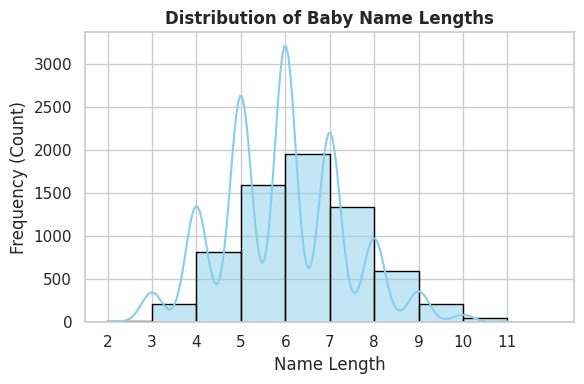

The structural mode (most common length) is: 6


In [6]:
lens = pd.DataFrame(columns=['length'])
lens['length'] = df['name'].astype(str).str.len()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))

max_len = int(lens['length'].max())
min_len = int(lens['length'].min())

sns.histplot(
    data=lens,
    x='length',
    bins=range(min_len, max_len + 2),
    kde=True,
    color='skyblue',
    edgecolor='black'
)

plt.title('Distribution of Baby Name Lengths', fontsize=12, fontweight='bold')
plt.xlabel('Name Length', fontsize=12)
plt.ylabel('Frequency (Count)', fontsize=12)
plt.xticks(range(min_len, max_len + 1))
plt.tight_layout()
plt.show()

print(f"The structural mode (most common length) is: {lens['length'].mode()[0]}")

In [7]:
df_bak = df.copy()

#### Gender ratios

In [8]:
ratio = df['gender'].value_counts()
ratio = ratio.reset_index(level=0)

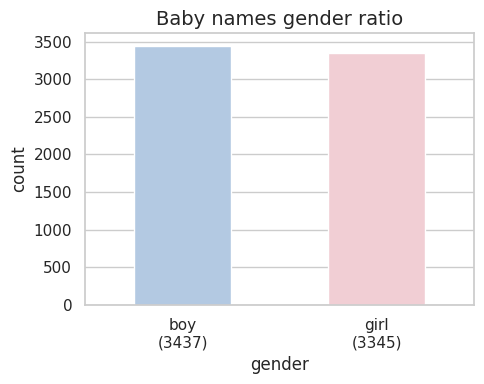

In [9]:
plt.figure(figsize=(5, 4))
sns.barplot(data=ratio, x='gender', y='count', hue='gender', width=0.5, palette=['#ABC9EA', '#F7C8D0'])
plt.xticks(['boy', 'girl'], [f"boy\n({ratio['count'][0]})", f"girl\n({ratio['count'][1]})"])
plt.title("Baby names gender ratio", fontsize=14)
plt.tight_layout()
plt.show()

It's not so bad, the dataset is well balanced, there' only around 100 names play difference, which is not so big deal.

#### Letter frequency chart

In [10]:
%%time
letter_count = {key: 0 for key in string.ascii_lowercase}

for idx in range(df.shape[0]):
  name = df['name'][idx].lower()
  for let in name:
    letter_count[let] += 1

letter_count = pd.DataFrame(letter_count, index=[0]).T.reset_index(level=0)

CPU times: user 30.3 ms, sys: 1.01 ms, total: 31.3 ms
Wall time: 33.1 ms


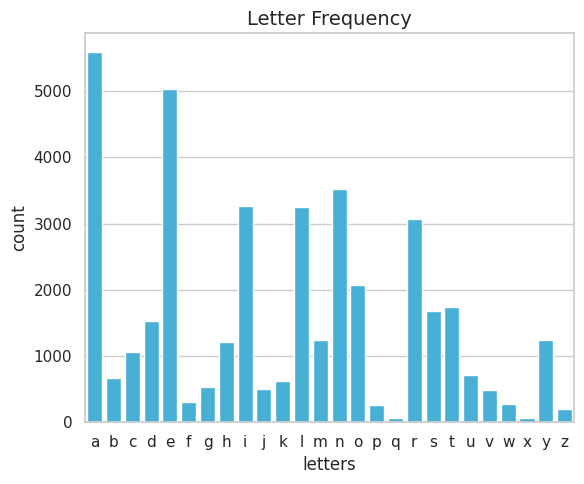

In [11]:
plt.figure(figsize=(6, 5))
sns.barplot(data=letter_count, x='index', y=0, color='#31BCEB')
plt.title("Letter Frequency", fontsize=14)
plt.xlabel('letters')
plt.ylabel('count')
plt.tight_layout()
plt.show()

I see letters 'q' and 'x' are the least used letters for names.

## Data preparation

In [12]:
# Encoding the genders
df['gender'] = df['gender'].apply(lambda g: 1 if g == 'boy' else 0)

# Convert names to lowercase
df['name'] = df['name'].apply(lambda x: x.lower())

#### Extending each name with 'start of sequence(SOS)' prefix, 'end of sequence(EOS)' postfix, and pad the name with 'space' up to the maximum length.


In [13]:
# Iterating through all the names in the dataset to find the longest name
max_len = 0
for idx in range(df.shape[0]):
  name = df['name'].iloc[idx]
  if len(name) > max_len:
    print(f"Newest longest name: {name}")
    max_len = len(name)
print(f"Maximum length of a name: {max_len}")

Newest longest name: john
Newest longest name: william
Newest longest name: clarence
Newest longest name: frederick
Newest longest name: christopher
Maximum length of a name: 11


In [14]:
# Adding the prefix, postfix, and the paddings
name_list = []
for idx in range(df.shape[0]):
  name = df['name'][idx].lower()
  lenn = len(name)

  temp_list = []
  temp_list.append("<SOS>")
  for let in name:
    temp_list.append(let)
  temp_list.append("<EOS>")
  for _ in range(max_len-lenn):
    temp_list.append(' ')
  name_list.append(temp_list)

In [15]:
# Results
name_list[:5]

[['<SOS>', 'j', 'o', 'h', 'n', '<EOS>', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
 ['<SOS>', 'w', 'i', 'l', 'l', 'i', 'a', 'm', '<EOS>', ' ', ' ', ' ', ' '],
 ['<SOS>', 'j', 'a', 'm', 'e', 's', '<EOS>', ' ', ' ', ' ', ' ', ' ', ' '],
 ['<SOS>', 'c', 'h', 'a', 'r', 'l', 'e', 's', '<EOS>', ' ', ' ', ' ', ' '],
 ['<SOS>', 'g', 'e', 'o', 'r', 'g', 'e', '<EOS>', ' ', ' ', ' ', ' ', ' ']]

#### Creating an array of tokens (letters and special symbols) that will be used to encode each name. A mapping from token to integer id and vice versa.


In [16]:
token_to_id = {" " : 0, "<SOS>" : 1, "<EOS>" : 2,}
token_to_id.update({token: id+3 for id, token in enumerate(string.ascii_lowercase)})
id_to_token = {val: key for key, val in token_to_id.items()}

#### Representing the each name as a sequence of integers using the mapping we just created. Each sequence should have the same length.


In [17]:
# A small function for conversion
def tokenize(name, token_to_id):
  tokens = []
  for token in name:
    tokens.append(token_to_id[token])
  return tokens

In [18]:
tokenized_names = []
for name in name_list:
  tokenized = tokenize(name, token_to_id)
  tokenized_names.append(tokenized)

In [19]:
tokenized_names[:5]

[[1, 12, 17, 10, 16, 2, 0, 0, 0, 0, 0, 0, 0],
 [1, 25, 11, 14, 14, 11, 3, 15, 2, 0, 0, 0, 0],
 [1, 12, 3, 15, 7, 21, 2, 0, 0, 0, 0, 0, 0],
 [1, 5, 10, 3, 20, 14, 7, 21, 2, 0, 0, 0, 0],
 [1, 9, 7, 17, 20, 9, 7, 2, 0, 0, 0, 0, 0]]

#### Splitting the dataset into training, valid, and test parts (80-10-10%)

In [20]:
X = np.array(tokenized_names)
y = df['gender'].to_numpy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, shuffle=True, test_size=0.2, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, shuffle=True, test_size=0.5, random_state=42)
print(f"Train size: {X_train.shape[0]}\nValid size: {X_valid.shape[0]}\nTest size: {X_test.shape[0]}")

Train size: 5425
Valid size: 678
Test size: 679


### Custom Dataset

In [21]:
class CDataset(Dataset):
  def __init__(self, X, y, transform=None, target_transform=None):
    self.X = X
    self.y = y
    self.transform = transform
    self.target_transform = target_transform

  def __len__(self):
    return self.X.shape[0]

  def __getitem__(self, idx):
    X = self.X[idx]
    y = self.y[idx]
    if self.transform:
        X = self.transform(X)
    if self.target_transform:
        y = self.target_transform(y)
    return X, y

In [22]:
train_dataset = CDataset(X_train, y_train)
valid_dataset = CDataset(X_valid, y_valid)
test_dataset = CDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

## Recurrent Neural Network

### This RNN network will contain:

1. Embedding layer;
2. Vanilla recurrent neural network block (RNN block will be imlemented from scratch using PyTorch);
3. Linear layer to transform the output of the RNN block into logits of the next token output;
4. Linear layer to transform the last token output of the RNN block to logit of gender;
5. A dropout layer to stabilize the model;
6. Sigmoid to transform the gender class logit to probability;


In [23]:
class VanillaRNNBlock(nn.Module):
  def __init__(self, input_size, hidden_size):
    super(VanillaRNNBlock, self).__init__()
    self.hidden_size = hidden_size
    self.x2h = nn.Linear(input_size, self.hidden_size, bias=True)
    self.h2h = nn.Linear(self.hidden_size, self.hidden_size, bias=False)
    self.tanh = nn.Tanh()

  def forward(self, x_t, h_prev):
    h_next = self.tanh(self.x2h(x_t) + self.h2h(h_prev))
    return h_next

In [24]:
class FullRNN(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64):
    super(FullRNN, self).__init__()
    self.hidden_size = hidden_size
    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.rnn = VanillaRNNBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  # This will initialize the hidden state for the RNN layer
  def init_hidden(self, batch_size, device):
    self.hidden_state = torch.zeros(batch_size, self.hidden_size, device=device)
    return self.hidden_state


  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device

    embedded = self.embedding(x)
    h_t = self.init_hidden(batch_size, device)
    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)

    for t in range(seq_len):
      x_t = embedded[:, t, :]
      h_t = self.rnn(x_t, h_t)
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)

    return char_logits, gender_probs

### Training the network using only loss for next letter prediction

In [25]:
# Declaring the model, optimizer, loss and the scheduler
rnn = FullRNN(len(id_to_token), hidden_size=512)
rnn = rnn.to(device)

optimizer = optim.Adam(rnn.parameters())
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.15, last_epoch=-1)
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

In [26]:
%%time
# Saving the losses to analyze them later
train_char_losses = []
train_gender_losses = []
valid_char_losses = []
valid_gender_losses = []

# Training loop, also tests
n_epochs = 10
for epoch in range(n_epochs):
  print(f"Epoch {epoch + 1:02d}:")
  avg_loss_chars_t, avg_loss_genders_t = train(model = rnn, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer, device=device, task="char")
  avg_loss_chars_v, avg_loss_genders_v = test(model = rnn, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device)
  scheduler.step()

  train_char_losses.append(avg_loss_chars_t)
  train_gender_losses.append(avg_loss_genders_t)
  valid_char_losses.append(avg_loss_chars_v)
  valid_gender_losses.append(avg_loss_genders_v)

Epoch 01:
     Loss(training): characters(multi): 2.3045 | gender(binary): 0.7060
     Loss (testing): characters(multi): 2.1931 | gender(binary): 0.6948
     Accuracy (avg): characters(multi): 30.77% | gender(binary): 47.49%
Epoch 02:
     Loss(training): characters(multi): 2.1334 | gender(binary): 0.6961
     Loss (testing): characters(multi): 2.1294 | gender(binary): 0.6967
     Accuracy (avg): characters(multi): 32.10% | gender(binary): 47.35%
Epoch 03:
     Loss(training): characters(multi): 2.0729 | gender(binary): 0.6999
     Loss (testing): characters(multi): 2.0948 | gender(binary): 0.6908
     Accuracy (avg): characters(multi): 32.60% | gender(binary): 52.36%
Epoch 04:
     Loss(training): characters(multi): 2.0223 | gender(binary): 0.6974
     Loss (testing): characters(multi): 2.0681 | gender(binary): 0.6856
     Accuracy (avg): characters(multi): 35.23% | gender(binary): 55.46%
Epoch 05:
     Loss(training): characters(multi): 1.9815 | gender(binary): 0.6992
     Loss (tes

### Implementing a method to generate names from the trained model:

1. Method will be stochastic — i.e. next letter should be sampled using probabilities based on logit level.
2. A prefix parameter to control the beginning of the name.
3. A parameter to control the stochasticity of the next letter. Usually this parameter is called temperature. Higher temperature produces more chaotic outputs, lower temperature converges to the single most likely output.

In [27]:
def generate_name(model, id_to_token, token_to_id, prefix=None, temperature=1, max_range=20, device="cpu", retn=False):
  model.eval()
  sos_id = token_to_id.get("<SOS>")
  eos_id = token_to_id.get("<EOS>")
  sequence_ids = [sos_id]

  if prefix:
    for char in prefix:
      char = char.lower()
      sequence_ids.append(token_to_id[char])

  with torch.no_grad():
    for _ in range(max_range - len(sequence_ids)):
      x_tensor = torch.tensor([sequence_ids], dtype=torch.long).to(device)

      char_logits, _ = model(x_tensor)
      last_char_logits = char_logits[0, -1, :]
      last_char_logits = last_char_logits / temperature
      probs = F.softmax(last_char_logits, dim=0)
      next_char_id = torch.multinomial(probs, num_samples=1).item()

      if next_char_id == eos_id:
        break

      sequence_ids.append(next_char_id)

  generated_name = "".join([id_to_token[idx] for idx in sequence_ids[1:]])
  if retn:
    return generated_name
  else:
    print(generated_name)

### Evaluation:

1. A loss convergence on train and valid data.

Earlier I had saved the train/validation losses, so we don't have to run the loop again.

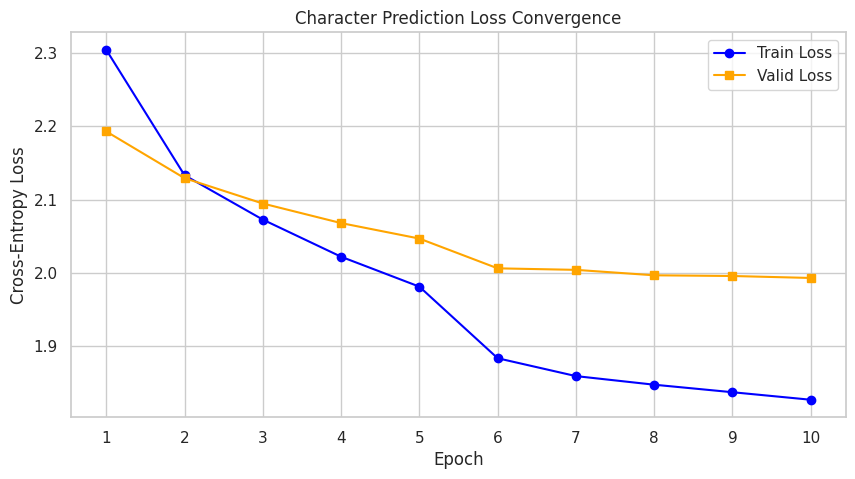

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, n_epochs + 1), train_char_losses, label='Train Loss', color='blue', marker='o')
plt.plot(range(1, n_epochs + 1), valid_char_losses, label='Valid Loss', color='orange', marker='s')
plt.title('Character Prediction Loss Convergence')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True)
plt.legend()
plt.xticks(range(1, n_epochs + 1))
plt.show()

### 2. 10 sample names. Are they even realistic?

The default prefix is `<SOS>` which initializes the model and the model will automatically pick the the next letters, and randomly choosing the temperature between 0.5-1.5

In [29]:
for _ in range(10):
  generate_name(
      model = rnn,
      id_to_token = id_to_token,
      token_to_id = token_to_id,
      temperature=np.random.uniform(0.5, 1.5),
      max_range=random.randrange(4, 14),
      device=device)

mard
rat
hinkel
robbe
samma
jayle
alex
davann
adis
aulyn


<h4>They are legit.</h4>

### 3. ROC AUC score with test dataset.

In [30]:
test(model = rnn, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device, roc_auc=roc_auc_score)

     ROC AUC score (test/avg): 0.5353
     Loss (testing): characters(multi): 1.9921 | gender(binary): 0.6980
     Accuracy (avg): characters(multi): 37.08% | gender(binary): 53.10%


(1.9920594822340658, 0.6979532284019268)

<h3>Is that any good? Yes, and no, the model only focuses on predicting the next letter so it can generate legit sounding names, but it pretty much flips a coin on predicting the gender of the name. Why? Because we used a multi-class loss which is only responsible for character prediction.</h3>

## Gated Recurrent Unit

We will just repeat the earlier steps for initializing, training, and evaluating the model.

In [31]:
class GRUBlock(nn.Module):
  def __init__(self, input_size, hidden_size):
    super(GRUBlock, self).__init__()
    self.hidden_size = hidden_size

    self.W_xr = nn.Parameter(torch.empty(input_size, self.hidden_size))
    self.W_xz = nn.Parameter(torch.empty(input_size, self.hidden_size))

    self.W_hr = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size))
    self.W_hz = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size))

    self.b_r = nn.Parameter(torch.empty(1, self.hidden_size))
    self.b_z = nn.Parameter(torch.empty(1, self.hidden_size))

    self.W_xh = nn.Parameter(torch.empty(input_size, self.hidden_size))
    self.W_hh = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size))
    self.b_h = nn.Parameter(torch.empty(1, self.hidden_size))

    self.init_weights()

  def init_weights(self):
    stdv = 1.0 / math.sqrt(self.hidden_size)
    for weight in self.parameters():
      weight.data.uniform_(-stdv, stdv)


  def forward(self, x_t, h_prev):
    r_t = torch.sigmoid(x_t @ self.W_xr + h_prev @ self.W_hr + self.b_r)
    z_t = torch.sigmoid(x_t @ self.W_xz + h_prev @ self.W_hz + self.b_z)
    h_tilde = torch.tanh(x_t @ self.W_xh + (r_t * h_prev) @ self.W_hh + self.b_h)
    h_next = z_t * h_prev + (1 - z_t) * h_tilde
    return h_next

In [32]:
class FullGRU(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64):
    super(FullGRU, self).__init__()
    self.hidden_size = hidden_size
    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.gru = GRUBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  def init_hidden(self, batch_size, device):
    self.hidden_state = torch.zeros(batch_size, self.hidden_size, device=device)
    return self.hidden_state


  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device

    embedded = self.embedding(x)
    h_t = self.init_hidden(batch_size, device)
    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)

    for t in range(seq_len):
      x_t = embedded[:, t, :]
      h_t = self.gru(x_t, h_t)
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)

    return char_logits, gender_probs

In [33]:
%%time
gru = FullGRU(len(id_to_token), hidden_size=512)
gru = gru.to(device)

optimizer = optim.Adam(gru.parameters())
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.15, last_epoch=-1)
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 12.8 ms, sys: 945 µs, total: 13.8 ms
Wall time: 15.8 ms


### Training the network using only loss for next letter prediction

In [34]:
%%time
train_char_losses = []
train_gender_losses = []
valid_char_losses = []
valid_gender_losses = []

n_epochs = 10
for epoch in range(n_epochs):
  print(f"Epoch {epoch + 1:02d}:")
  avg_loss_chars_t, avg_loss_genders_t = train(model = gru, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer, device=device, task="char")
  avg_loss_chars_v, avg_loss_genders_v = test(model = gru, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device)
  scheduler.step()

  train_char_losses.append(avg_loss_chars_t)
  train_gender_losses.append(avg_loss_genders_t)
  valid_char_losses.append(avg_loss_chars_v)
  valid_gender_losses.append(avg_loss_genders_v)

Epoch 01:
     Loss(training): characters(multi): 2.3437 | gender(binary): 0.7230
     Loss (testing): characters(multi): 2.1896 | gender(binary): 0.7162
     Accuracy (avg): characters(multi): 30.82% | gender(binary): 47.64%
Epoch 02:
     Loss(training): characters(multi): 2.1169 | gender(binary): 0.7061
     Loss (testing): characters(multi): 2.0968 | gender(binary): 0.7207
     Accuracy (avg): characters(multi): 33.28% | gender(binary): 47.64%
Epoch 03:
     Loss(training): characters(multi): 2.0310 | gender(binary): 0.7099
     Loss (testing): characters(multi): 2.0460 | gender(binary): 0.7164
     Accuracy (avg): characters(multi): 34.48% | gender(binary): 47.64%
Epoch 04:
     Loss(training): characters(multi): 1.9578 | gender(binary): 0.7053
     Loss (testing): characters(multi): 2.0221 | gender(binary): 0.7123
     Accuracy (avg): characters(multi): 36.22% | gender(binary): 47.64%
Epoch 05:
     Loss(training): characters(multi): 1.8884 | gender(binary): 0.7032
     Loss (tes

### Evaluation


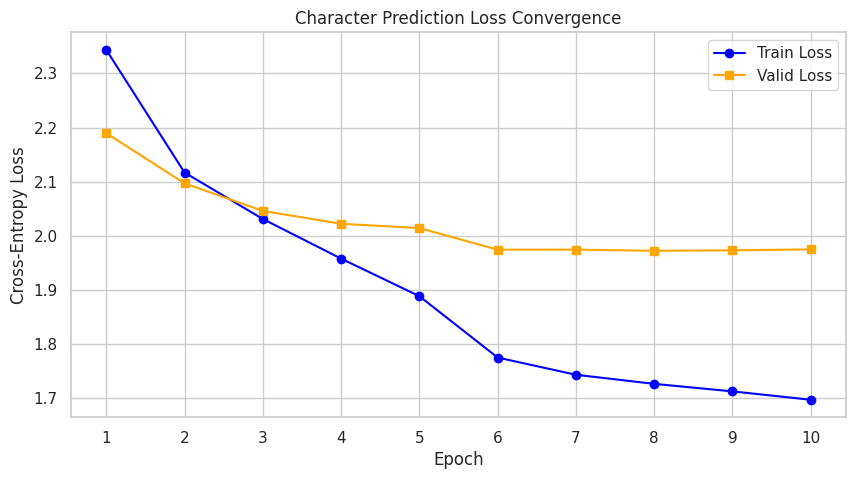

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, n_epochs + 1), train_char_losses, label='Train Loss', color='blue', marker='o')
plt.plot(range(1, n_epochs + 1), valid_char_losses, label='Valid Loss', color='orange', marker='s')
plt.title('Character Prediction Loss Convergence')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True)
plt.legend()
plt.xticks(range(1, n_epochs + 1))
plt.show()

<h3>It was just about to start overfit, you can clearly see it by the trends of validation loss.</h3>

### Sample names

In [36]:
for _ in range(10):
  generate_name(
      model = gru,
      id_to_token = id_to_token,
      token_to_id = token_to_id,
      temperature=np.random.uniform(0.5, 1.5),
      max_range=random.randrange(4, 14),
      device=device)

lucie
dol
jor
tall
oral
shaqui
dajai
ida
bra
sana


<h3>Yeah, they sound pretty realistic. </h3>

### ROC_AUC score on test dataset

In [37]:
test(model = gru, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device, roc_auc=roc_auc_score)

     ROC AUC score (test/avg): 0.5769
     Loss (testing): characters(multi): 1.9752 | gender(binary): 0.7178
     Accuracy (avg): characters(multi): 38.64% | gender(binary): 47.79%


(1.9752206872698128, 0.7178479169322326)

## LSTM


In [38]:
class LSTMBlock(nn.Module):
  def __init__(self, input_size, hidden_size, sigma=0.01):
    super(LSTMBlock, self).__init__()
    init_weight = lambda *shape: nn.Parameter(torch.rand(*shape) * sigma)
    triple = lambda: (init_weight(input_size, hidden_size),
                     init_weight(hidden_size, hidden_size),
                     nn.Parameter(torch.zeros(hidden_size)))

    self.W_xi, self.W_hi, self.b_i = triple()
    self.W_xf, self.W_hf, self.b_f = triple()
    self.W_xo, self.W_ho, self.b_o = triple()
    self.W_xc, self.W_hc, self.b_c = triple()

  def forward(self, x_t, states_prev):
    h_prev, c_prev = states_prev

    i_t = torch.sigmoid(x_t @ self.W_xi + h_prev @ self.W_hi + self.b_i)
    f_t = torch.sigmoid(x_t @ self.W_xf + h_prev @ self.W_hf + self.b_f)
    o_t = torch.sigmoid(x_t @ self.W_xo + h_prev @ self.W_ho + self.b_o)
    c_tilde = torch.tanh(x_t @ self.W_xc + h_prev @ self.W_hc + self.b_c)

    c_next = f_t * c_prev + i_t * c_tilde
    h_next = o_t * torch.tanh(c_next)
    return (h_next, c_next)

In [39]:
class FullLSTM(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64):
    super(FullLSTM, self).__init__()
    self.hidden_size = hidden_size
    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.lstm = LSTMBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  # This time LSTM has 2 hidden states, short term memory and long term memory
  def init_hidden(self, batch_size, device):
    h_0 = torch.zeros(batch_size, self.hidden_size, device=device)
    c_0 = torch.zeros(batch_size, self.hidden_size, device=device)
    return (h_0, c_0)


  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device

    embedded = self.embedding(x)
    states_t = self.init_hidden(batch_size, device)

    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)

    for t in range(seq_len):
      x_t = embedded[:, t, :]
      states_t = self.lstm(x_t, states_t)
      h_t = states_t[0]
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)

    return char_logits, gender_probs

In [40]:
%%time
lstm = FullLSTM(len(id_to_token), hidden_size=512)
lstm = lstm.to(device)

optimizer = optim.Adam(lstm.parameters())
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.15, last_epoch=-1)
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 13.6 ms, sys: 992 µs, total: 14.6 ms
Wall time: 25.8 ms


### Training the network using only loss for next letter prediction

In [41]:
%%time
train_char_losses = []
train_gender_losses = []
valid_char_losses = []
valid_gender_losses = []

n_epochs = 10
for epoch in range(n_epochs):
  print(f"Epoch {epoch + 1:02d}:")
  avg_loss_chars_t, avg_loss_genders_t = train(model = lstm, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer, device=device, task="char")
  avg_loss_chars_v, avg_loss_genders_v = test(model = lstm, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device)
  scheduler.step()

  train_char_losses.append(avg_loss_chars_t)
  train_gender_losses.append(avg_loss_genders_t)
  valid_char_losses.append(avg_loss_chars_v)
  valid_gender_losses.append(avg_loss_genders_v)

Epoch 01:
     Loss(training): characters(multi): 2.4087 | gender(binary): 0.6979
     Loss (testing): characters(multi): 2.2416 | gender(binary): 0.6965
     Accuracy (avg): characters(multi): 28.44% | gender(binary): 47.64%
Epoch 02:
     Loss(training): characters(multi): 2.1708 | gender(binary): 0.7001
     Loss (testing): characters(multi): 2.1427 | gender(binary): 0.6999
     Accuracy (avg): characters(multi): 31.37% | gender(binary): 47.64%
Epoch 03:
     Loss(training): characters(multi): 2.0865 | gender(binary): 0.7010
     Loss (testing): characters(multi): 2.0976 | gender(binary): 0.6978
     Accuracy (avg): characters(multi): 32.10% | gender(binary): 47.64%
Epoch 04:
     Loss(training): characters(multi): 2.0245 | gender(binary): 0.7068
     Loss (testing): characters(multi): 2.0589 | gender(binary): 0.7131
     Accuracy (avg): characters(multi): 35.62% | gender(binary): 47.64%
Epoch 05:
     Loss(training): characters(multi): 1.9631 | gender(binary): 0.7133
     Loss (tes

### Evaluation

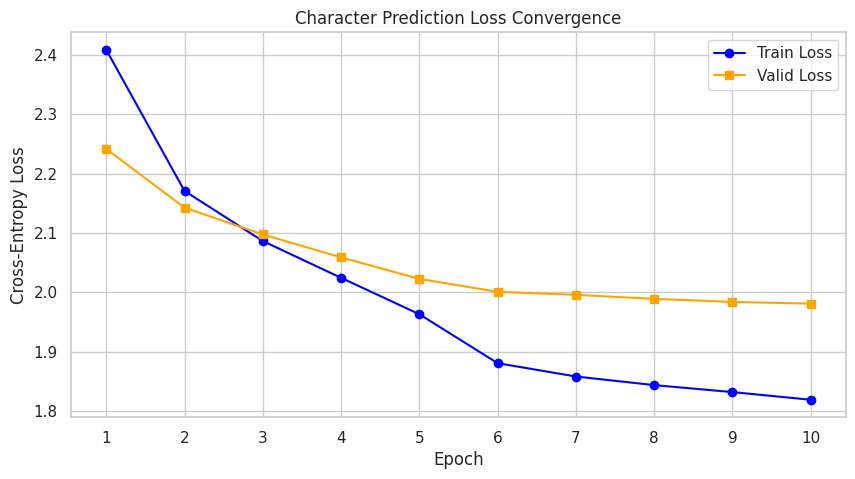

In [42]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, n_epochs + 1), train_char_losses, label='Train Loss', color='blue', marker='o')
plt.plot(range(1, n_epochs + 1), valid_char_losses, label='Valid Loss', color='orange', marker='s')
plt.title('Character Prediction Loss Convergence')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True)
plt.legend()
plt.xticks(range(1, n_epochs + 1))
plt.show()

#### Sample names

In [43]:
for _ in range(10):
  generate_name(
      model = lstm,
      id_to_token = id_to_token,
      token_to_id = token_to_id,
      temperature=np.random.uniform(0.5, 1.5),
      max_range=random.randrange(4, 14),
      device=device)

halbet
cath
elice
timmy
eves
haron
jolian
cor
derri
andrea


### ROC_AUC score

In [44]:
test(model = lstm, dataloader = valid_loader, loss_multi = loss_multi, loss_bin = loss_bin, device=device, roc_auc=roc_auc_score)

     ROC AUC score (test/avg): 0.4554
     Loss (testing): characters(multi): 1.9812 | gender(binary): 0.7294
     Accuracy (avg): characters(multi): 37.94% | gender(binary): 47.64%


(1.9812155061766812, 0.7293686951156211)

## Model comparison

<h3>What is Perplexity metric?</h3>

Perplexity is a metric that measures the uncertainty of a model's predictions, it quantifies how well the model predicts the next word in a sequence. When a model makes a prediction, it assigns probabilities to possible next words.

Mathematically, perplexity is calculated as:

<code>Perplexity = 2 ** H(p)</code>

H(p) is the entropy of the model's predictions.

Entropy measures the level of uncertainty in the model's output. Lower entropy means the model is more certain about its predictions and therefore, the perplexity is lower.

Perplexity indicates the level of confidence the model has in its prediction—lower perplexity suggests higher confidence and better performance in predicting the next word, while higher perplexity signals more uncertainty and less reliability. In simple terms, perplexity represents the number of potential options the model is considering when making its prediction.


<br>
<h3>Its relation between Cross Entropy Loss</h3>

Let a sequence of actual target characters be $X = (x_1, x_2, \dots, x_N)$.
Perplexity is defined as the inverse probability of the sequence, normalized by the number of tokens (the geometric mean of the inverse probabilities):

$$PPL(X) = \sqrt[N]{\frac{1}{P(x_1, x_2, \dots, x_N)}}$$

Using the chain rule of probability for an autoregressive model:


$$P(x_1, \dots, x_N) = \prod_{i=1}^{N} P(x_i \mid x_{1:i-1})$$

Substitute this into the PPL equation:


$$PPL(X) = \left( \prod_{i=1}^{N} P(x_i \mid x_{1:i-1}) \right)^{-\frac{1}{N}}$$

Take the natural logarithm ($\ln$) of both sides:


$$\ln(PPL(X)) = -\frac{1}{N} \sum_{i=1}^{N} \ln P(x_i \mid x_{1:i-1})$$

The right side of this equation is exactly the mathematical definition of Cross-Entropy Loss (CE)!
Therefore:


$$\ln(PPL) = CE \implies \mathbf{PPL = e^{CE}}$$

(Note: If Cross-Entropy uses base-2 log, it's $2^{CE}$. PyTorch uses natural log base $e$).

### Implementing 2 versions of this metric, with and without cross entropy loss.

In [45]:
# A function to get the raw logits
def get_logits(model, dataloader, device):
  model.eval()
  with torch.no_grad():
    for x_batch, _ in dataloader:
      x_batch = x_batch.to(device)
      char_logits, _ = model(x_batch)
      return char_logits, x_batch

In [46]:
def perplexity_with_ce(logits, targets, pad_idx=0):
  logits_flat = logits.reshape(-1, logits.size(-1))
  targets_flat = targets.reshape(-1)

  ce_loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=pad_idx)
  ppe = torch.exp(ce_loss).item()
  return ppe

def perplexity_without_ce(logits, targets, pad_idx=0):
  probs = F.softmax(logits, dim=-1)

  probs_flat = probs.reshape(-1, logits.size(-1))
  targets_flat = targets.reshape(-1)

  mask = (targets_flat != pad_idx)
  valid_targets = targets_flat[mask]
  valid_probs = probs_flat[mask]

  true_class_probs = valid_probs[torch.arange(len(valid_targets)), valid_targets]
  N = len(valid_targets)
  avg_neg_log_prob = -torch.sum(torch.log(true_class_probs)) / N
  return torch.exp(avg_neg_log_prob).item()

In [47]:
char_logits, x_batch = get_logits(rnn, valid_loader, device)
print(f"with CE: {perplexity_with_ce(char_logits, x_batch)}")
print(f"without CE: {perplexity_without_ce(char_logits, x_batch)}")

with CE: 160.39784240722656
without CE: 160.39784240722656


### Deriving the value of this metric for a "random" untrained model

In [48]:
models = {"RNN" : FullRNN, "GRU" : FullGRU, "LSTM" : FullLSTM}
random_model  = random.choice(list(models.keys()))
print(f"THE RANDOM MODEL OF THE DAY: {random_model}")

THE RANDOM MODEL OF THE DAY: GRU


In [49]:
tmodel = models[random_model](len(id_to_token), hidden_size=512)
tmodel.to(device)
char_logits, x_batch = get_logits(tmodel, valid_loader, device)
print(f"with Cross-Entropy: {perplexity_with_ce(char_logits, x_batch)}")
print(f"without Cross-Entropy: {perplexity_without_ce(char_logits, x_batch)}")

with Cross-Entropy: 30.412742614746094
without Cross-Entropy: 30.412742614746094


<h3>We can see the perplexity score is around 29 each time, because there are only 29 characters/ids, so by the simplified formula we go: <code>1/(1/29)</code> the result is roughly around 29% </h3>

### Computing the value of this metric on a trained model

In [50]:
# From the previous we still have RNN/GRU/LSTM that are trained models.
char_logits, x_batch = get_logits(lstm, valid_loader, device)
print(f"with Cross-Entropy: {perplexity_with_ce(char_logits, x_batch)}")
print(f"without Cross-Entropy: {perplexity_without_ce(char_logits, x_batch)}")

with Cross-Entropy: 216.25013732910156
without Cross-Entropy: 216.25013732910156


### Compare the models


In [51]:
# A little class to hide print statements.
class HiddenPrints:
    def __enter__(self):
        self._original_stdout = sys.stdout
        sys.stdout = open(os.devnull, 'w')

    def __exit__(self, exc_type, exc_val, exc_tb):
        sys.stdout.close()
        sys.stdout = self._original_stdout

In [52]:
ppe_results = pd.DataFrame(columns=['model', 'with_ce', 'without_ce'])

#rnn
char_logits, x_batch = get_logits(rnn, valid_loader, device)
print("RNN:")
with_ce = perplexity_with_ce(char_logits, x_batch)
without_ce = perplexity_without_ce(char_logits, x_batch)
print(f"with Cross-Entropy: {with_ce}")
print(f"without Cross-Entropy: {without_ce}")
ppe_results.loc[len(ppe_results)] = ['RNN', with_ce, without_ce]

#GRU
char_logits, x_batch = get_logits(gru, valid_loader, device)
print("\nGRU:")
with_ce = perplexity_with_ce(char_logits, x_batch)
without_ce = perplexity_without_ce(char_logits, x_batch)
ppe_results.loc[len(ppe_results)] = ['GRU', with_ce, without_ce]
print(f"with Cross-Entropy: {with_ce}")
print(f"without Cross-Entropy: {without_ce}")

#LSTM
char_logits, x_batch = get_logits(lstm, valid_loader, device)
print("\nLSTM:")
with_ce = perplexity_with_ce(char_logits, x_batch)
without_ce = perplexity_without_ce(char_logits, x_batch)
ppe_results.loc[len(ppe_results)] = ['LSTM', with_ce, without_ce]
print(f"with Cross-Entropy: {with_ce}")
print(f"without Cross-Entropy: {without_ce}")

RNN:
with Cross-Entropy: 149.92991638183594
without Cross-Entropy: 149.92991638183594

GRU:
with Cross-Entropy: 233.3682403564453
without Cross-Entropy: 233.3683624267578

LSTM:
with Cross-Entropy: 193.5452880859375
without Cross-Entropy: 193.54537963867188


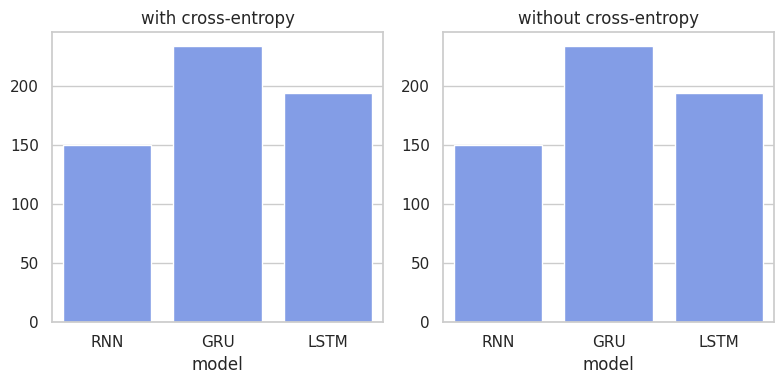

In [53]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, nrows=1, figsize=(8, 4))
sns.barplot(data=ppe_results, x="model", y='with_ce', ax=ax1, color="#7295F6")
sns.barplot(data=ppe_results, x="model", y='without_ce', ax=ax2, color="#7295F6")
ax1.set_title("with cross-entropy")
ax2.set_title("without cross-entropy")
ax1.set_ylabel("")
ax2.set_ylabel("")
plt.tight_layout()
plt.show()

<h4>These models are not that good at all.</h4>

## Gender classification

### Let's train RNN, GRU, and LSTM, but with a different loss function: Binary Cross Entropy Loss.

In [54]:
%%time
rnn = FullRNN(len(id_to_token), hidden_size=512).to(device)
gru = FullGRU(len(id_to_token), hidden_size=512).to(device)
lstm = FullLSTM(len(id_to_token), hidden_size=512).to(device)

# Each model has to have different optimizers and schedulers for each optimizer
optimizer_rnn = optim.Adam(rnn.parameters())
optimizer_gru = optim.Adam(gru.parameters())
optimizer_lstm = optim.Adam(lstm.parameters())

scheduler_rnn = optim.lr_scheduler.StepLR(optimizer_rnn, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_gru = optim.lr_scheduler.StepLR(optimizer_gru, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_lstm = optim.lr_scheduler.StepLR(optimizer_lstm, step_size=5, gamma=0.15, last_epoch=-1)

# But we can re-use the same loss function again and again, because it just calculates the error.
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 19.3 ms, sys: 8.01 ms, total: 27.3 ms
Wall time: 28.2 ms


In [55]:
%%time
res_rnn = pd.DataFrame(columns=["epoch", "model", "Type(Loss/Acc)", "Loss"])
res_gru = pd.DataFrame(columns=["epoch", "model", "Type(Loss/Acc)", "Loss"])
res_lstm = pd.DataFrame(columns=["epoch", "model", "Type(Loss/Acc)", "Loss"])

n_epochs = 10
for epoch in range(n_epochs):
  print(f"Epoch {epoch}:")
  print("RNN:")
  rnn_train = train(model = rnn, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer_rnn, device=device, logsoftmax=True, task="gender")
  rnn_test = test(model = rnn, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device, roc_auc=roc_auc_score, return_all=True, logsoftmax=True)
  scheduler_rnn.step()

  print("GRU")
  gru_train = train(model = gru, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer_gru, device=device, logsoftmax=True, task="gender")
  gru_test = test(model = gru, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device, roc_auc=roc_auc_score, return_all=True, logsoftmax=True)
  scheduler_gru.step()

  print("LSTM")
  lstm_train = train(model = lstm, dataloader = train_loader, loss_multi = loss_multi, loss_bin = loss_bin, optimizer=optimizer_lstm, device=device, logsoftmax=True, task="gender")
  lstm_test = test(model = lstm, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device, roc_auc=roc_auc_score, return_all=True, logsoftmax=True)
  scheduler_lstm.step()
  print("\n")


  # train() returns = avg_loss_chars, avg_loss_genders
  # test() returns = ((avg_loss_chars, avg_loss_genders), (avg_char_acc, avg_bin_acc), avg_roc)
  res_rnn.loc[len(res_rnn)] = [epoch, "RNN", "train", rnn_train[1]]
  res_rnn.loc[len(res_rnn)] = [epoch, "RNN", "valid", rnn_test[0][1]]

  res_gru.loc[len(res_gru)] = [epoch, "GRU", "train", gru_train[1]]
  res_gru.loc[len(res_gru)] = [epoch, "GRU", "valid", gru_test[0][1]]

  res_lstm.loc[len(res_lstm)] = [epoch, "LSTM", "train", lstm_train[1]]
  res_lstm.loc[len(res_lstm)] = [epoch, "LSTM", "valid", lstm_test[0][1]]

Epoch 0:
RNN:
     Loss(training): characters(multi): 3.4199 | gender(binary): 0.5126
     ROC AUC score (test/avg): 0.8756
     Loss (testing): characters(multi): 3.4098 | gender(binary): 0.4448
     Accuracy (avg): characters(multi): 3.26% | gender(binary): 80.83%
GRU
     Loss(training): characters(multi): 3.3664 | gender(binary): 0.4987
     ROC AUC score (test/avg): 0.8771
     Loss (testing): characters(multi): 3.3655 | gender(binary): 0.4825
     Accuracy (avg): characters(multi): 3.09% | gender(binary): 77.29%
LSTM
     Loss(training): characters(multi): 3.3671 | gender(binary): 0.5445
     ROC AUC score (test/avg): 0.8600
     Loss (testing): characters(multi): 3.3635 | gender(binary): 0.4673
     Accuracy (avg): characters(multi): 0.99% | gender(binary): 79.79%


Epoch 1:
RNN:
     Loss(training): characters(multi): 3.4251 | gender(binary): 0.4511
     ROC AUC score (test/avg): 0.8805
     Loss (testing): characters(multi): 3.4279 | gender(binary): 0.4388
     Accuracy (avg):

Accuracy is pretty based as usual.

### Evaluation

#### Loss convergence on training and valid data

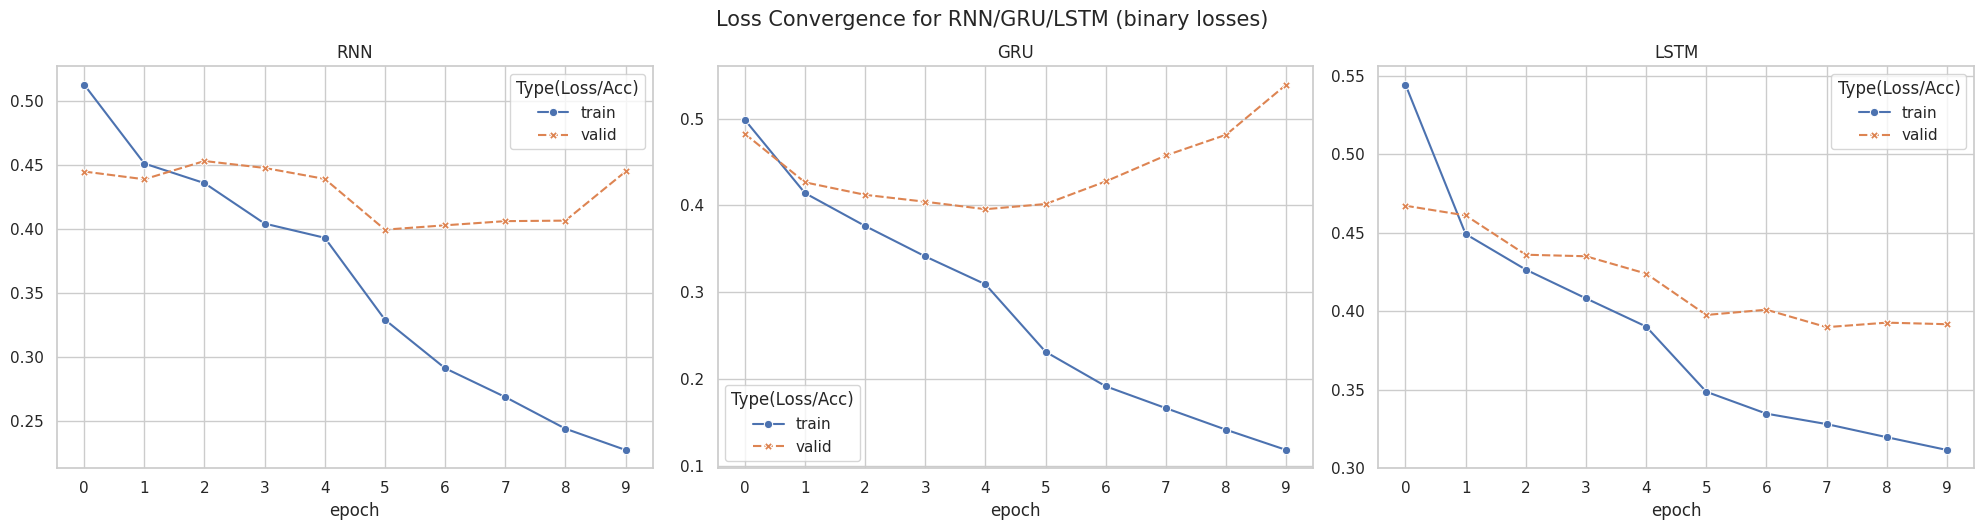

In [56]:
# This time we use seaborn as it's more efficient
fig, axes = plt.subplots(ncols=3, nrows=1, figsize=(20, 5.5))
sns.lineplot(data=res_rnn, x="epoch", y="Loss", hue="Type(Loss/Acc)", markers=True, style="Type(Loss/Acc)", legend="brief", ax=axes[0])
sns.lineplot(data=res_gru, x="epoch", y="Loss", hue="Type(Loss/Acc)", markers=True, style="Type(Loss/Acc)", legend="brief", ax=axes[1])
sns.lineplot(data=res_lstm, x="epoch", y="Loss", hue="Type(Loss/Acc)", markers=True, style="Type(Loss/Acc)", legend="brief", ax=axes[2])

for ax, nm in zip(axes, ["RNN", "GRU", "LSTM"]):
  ax.set_title(nm)
  ax.set_ylabel("")
  ax.set_xticks(range(0, n_epochs))

fig.suptitle("Loss Convergence for RNN/GRU/LSTM (binary losses)", y=0.96, fontsize=15)
plt.tight_layout()
plt.show()

<h3>RNN and GRU models are overfitting.</h3>

#### Generating sample names. Are they still realistic?

In [57]:
genn = pd.DataFrame(columns=['model', 'name'])
for model in [rnn, gru, lstm]:
  md = model.__class__.__name__
  for _ in range(10):
    name = generate_name(
        model = model,
        id_to_token = id_to_token,
        token_to_id = token_to_id,
        temperature=np.random.uniform(0.5, 1.5),
        max_range=random.randrange(4, 14),
        device=device,
        retn=True)
    genn.loc[len(genn)] = [md, name]

genn = genn.assign(row=genn.groupby("model").cumcount()).pivot(index="row", columns="model", values="name").reset_index(drop=True)

In [58]:
genn

model,FullGRU,FullLSTM,FullRNN
0,haabdfs,xqiubzwosdbd,hhgppjm
1,cpnexb,epuyhdqy,rbxj<SOS>
2,ytw,,zglwdm
3,xkb <SOS>huhwt,mrnfnd,qxwj<SOS>lto
4,al<SOS>ydiguft,recu,guld
5,qyk,wgr,d zm
6,pyqqkv<SOS>ac,sgqrwl,dctdw<SOS>ub
7,cbof,j h exd,hjhd
8,dmddlbylvdm,wf<SOS>e,oq
9,ylurbz<SOS>,k<SOS>ab p,rix tcr


<h3>Now the model only cares about preding the gender of the name, because I'm only calculating BCELoss() for binary classification.</h3>

#### Predicting the gender of the names from the test dataset and the ROC AUC score.

In [59]:
for model in [rnn, gru, lstm]:
  print(f"{model.__class__.__name__}:")
  test(model=model, dataloader=test_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device, roc_auc=roc_auc_score)

FullRNN:
     ROC AUC score (test/avg): 0.9100
     Loss (testing): characters(multi): 3.4469 | gender(binary): 0.4211
     Accuracy (avg): characters(multi): 3.39% | gender(binary): 84.83%
FullGRU:
     ROC AUC score (test/avg): 0.9223
     Loss (testing): characters(multi): 3.3824 | gender(binary): 0.4513
     Accuracy (avg): characters(multi): 3.22% | gender(binary): 86.30%
FullLSTM:
     ROC AUC score (test/avg): 0.9117
     Loss (testing): characters(multi): 3.3727 | gender(binary): 0.3834
     Accuracy (avg): characters(multi): 3.76% | gender(binary): 84.98%


<h3>It's obvious that these models are the worst on predicting the next letters now.</h3>

## Vanishing Gradient problem.
### Taking a subset of the training dataset where the length of the names is equal to their mode.

In [60]:
mode_length = df['name'].str.len().mode()[0]
df_fixed = df[df['name'].str.len()==mode_length].copy()
max_name_lenght = mode_length+2
print(f"Mode lenth: {mode_length}")

Mode lenth: 6


### Implementing the collection of gradients during model fitting for the embedding layer. The collected tensor will have the shape (n_epochs, max_name_length, n_tokens, embedding_size)

In [61]:
def collect_grads(module, grad_input, grad_output):
  g = grad_output[0].detach()
  x = module.current_input

  for b in range(x.size(0)):
    for t in range(x.size(1)):
      token_idx = x[b, t]
      module.epoch_grads[t, token_idx] += g[b, t]

In [62]:
class DebugRNN(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64, device="cpu"):
    super(DebugRNN, self).__init__()
    self.hidden_size = hidden_size

    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.embedding.epoch_grads = torch.zeros(max_name_lenght, vocab_size, embedding_dim, device=device)
    # This is where we connect the hook:
    self.embedding.register_full_backward_hook(collect_grads)

    self.rnn = VanillaRNNBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  def init_hidden(self, batch_size, device):
    self.hidden_state = torch.zeros(batch_size, self.hidden_size, device=device)
    return self.hidden_state


  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device

    self.embedding.current_input = x
    embedded = self.embedding(x)

    h_t = self.init_hidden(batch_size, device)
    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)
    for t in range(seq_len):
      x_t = embedded[:, t, :]
      h_t = self.rnn(x_t, h_t)
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)
    return char_logits, gender_probs

In [63]:
%%time
drnn = DebugRNN(len(id_to_token), hidden_size=512, device=device)
drnn = drnn.to(device)

optimizer = optim.Adam(drnn.parameters())
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 5.31 ms, sys: 0 ns, total: 5.31 ms
Wall time: 5.71 ms


### Debuging the gradient collection with batch_size=1 and n_epochs=1:

#### The norm of each vector along the last dimension. We will get a tensor with shape: (1, max_name_length, n_tokens)

In [64]:
x_test, y_test = df_fixed.sample(1).iloc[0]

name = x_test.lower()
temp_list = []
temp_list.append("<SOS>")
for let in name:
  temp_list.append(let)
temp_list.append("<EOS>")

x_test = tokenize(temp_list, token_to_id)
x_test, y_test = torch.tensor([x_test]), torch.tensor([y_test], dtype=torch.float32)
x_test, y_test = x_test.to(device), y_test.to(device)

char_logits, gender_probs = drnn(x_test)
loss = loss_bin(gender_probs, y_test)
loss.backward()

grad_norms = torch.norm(drnn.embedding.epoch_grads, dim=-1)
grad_norms_debug = grad_norms.unsqueeze(0)
print(f"{grad_norms_debug.shape}")

torch.Size([1, 8, 29])


sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


#### Comparing which tokens have non-zero gradient norm with the tokens of the names (note that register_backward_hook will collect the gradient from the last token to the first).


In [65]:
for t in range(x_test.size(0)):
  token = x_test[t, 0].item()
  normal_val = grad_norms[t, token].item()
  print(f"Time step: {t}, Token: {token} | Gradient norm: {normal_val:.4f}")
  non_zeros = (grad_norms[0]>0).nonzero(as_tuple=True)[0]
  print(f"Tokens with nonzero gradients: t={t}: {non_zeros.tolist()}")

Time step: 0, Token: 1 | Gradient norm: 0.0006
Tokens with nonzero gradients: t=0: [1]


### Computing the Frobenius norm of the gradient matrix for each epoch and token position. The resulting tensor should have the form: (n_epochs, max_name_length).


In [66]:
%%time
name_list = []
for idx in range(df_fixed.shape[0]):
  name = df_fixed['name'].iloc[idx].lower()
  lenn = len(name)

  temp_list = []
  temp_list.append("<SOS>")
  for let in name:
    temp_list.append(let)
  temp_list.append("<EOS>")
  name_list.append(temp_list)

tokenized_names = []
for name in name_list:
  tokenized = tokenize(name, token_to_id)
  tokenized_names.append(tokenized)

X_db = np.array(tokenized_names)
y_db = df_fixed['gender'].to_numpy()

CPU times: user 17.7 ms, sys: 0 ns, total: 17.7 ms
Wall time: 17.5 ms


In [67]:
X_train_db, X_valid_db, y_train_db, y_valid_db = train_test_split(X_db, y_db, random_state=42, shuffle=True, test_size=0.2)

train_dataset_db = CDataset(X_train_db, y_train_db)
valid_dataset_db = CDataset(X_valid_db, y_valid_db)

train_loader_db = DataLoader(train_dataset_db, batch_size=32, shuffle=True)
valid_loader_db = DataLoader(valid_dataset_db, batch_size=32, shuffle=True)

### Taking the mean over the epochs and Frobenius Norms computations below. Models will be trained for gender classification task. Then we will compare the distribution of mean gradient norm over token position for RNN, GRU, and LSTM architectures.


In [68]:
# Hooking up the other 2 models as well.
class DebugGRU(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64, device="cpu"):
    super(DebugGRU, self).__init__()
    self.hidden_size = hidden_size
    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.embedding.epoch_grads = torch.zeros(max_name_lenght, vocab_size, embedding_dim, device=device)
    self.embedding.register_full_backward_hook(collect_grads)
    self.gru = GRUBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  def init_hidden(self, batch_size, device):
    self.hidden_state = torch.zeros(batch_size, self.hidden_size, device=device)
    return self.hidden_state

  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device
    self.embedding.current_input = x
    embedded = self.embedding(x)
    h_t = self.init_hidden(batch_size, device)
    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)

    for t in range(seq_len):
      x_t = embedded[:, t, :]
      h_t = self.gru(x_t, h_t)
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)
    return char_logits, gender_probs


class DebugLSTM(nn.Module):
  def __init__(self, vocab_size, hidden_size=256, embedding_dim=64, device="cpu"):
    super(DebugLSTM, self).__init__()
    self.hidden_size = hidden_size
    self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
    self.embedding.epoch_grads = torch.zeros(max_name_lenght, vocab_size, embedding_dim, device=device)
    self.embedding.register_full_backward_hook(collect_grads)
    self.lstm = LSTMBlock(input_size=embedding_dim, hidden_size=self.hidden_size)
    self.char_fc = nn.Linear(self.hidden_size, vocab_size)
    self.gender_fc = nn.Linear(self.hidden_size, 1)
    self.sigmoid = nn.Sigmoid()
    self.dropout = nn.Dropout(0.2)

  def init_hidden(self, batch_size, device):
    h_0 = torch.zeros(batch_size, self.hidden_size, device=device)
    c_0 = torch.zeros(batch_size, self.hidden_size, device=device)
    return (h_0, c_0)

  def forward(self, x):
    batch_size, seq_len = x.shape
    device = x.device
    self.embedding.current_input = x
    embedded = self.embedding(x)
    states_t = self.init_hidden(batch_size, device)
    all_hidden_states = torch.zeros(batch_size, seq_len, self.hidden_size, device=device)
    for t in range(seq_len):
      x_t = embedded[:, t, :]
      states_t = self.lstm(x_t, states_t)
      h_t = states_t[0]
      all_hidden_states[:, t, :] = h_t

    all_hidden_states = self.dropout(all_hidden_states)
    last_hidden = all_hidden_states[:, -1, :]
    char_logits = self.char_fc(all_hidden_states)
    gender_logits = self.gender_fc(last_hidden).squeeze(-1)
    gender_probs = self.sigmoid(gender_logits)
    return char_logits, gender_probs

In [69]:
%%time
drnn = DebugRNN(len(id_to_token), hidden_size=512, device=device)
dgru = DebugGRU(len(id_to_token), hidden_size=512, device=device)
dlstm = DebugLSTM(len(id_to_token), hidden_size=512, device=device)
drnn = drnn.to(device)
dgru = dgru.to(device)
dlstm = dlstm.to(device)

optimizer_drnn = optim.Adam(drnn.parameters())
optimizer_dgru = optim.Adam(dgru.parameters())
optimizer_dlstm = optim.Adam(dlstm.parameters())

scheduler_rnn = optim.lr_scheduler.StepLR(optimizer_rnn, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_gru = optim.lr_scheduler.StepLR(optimizer_gru, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_lstm = optim.lr_scheduler.StepLR(optimizer_lstm, step_size=5, gamma=0.15, last_epoch=-1)

loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 22.8 ms, sys: 8 ms, total: 30.8 ms
Wall time: 31.7 ms


In [70]:
n_epochs = 10
all_epochs_grads_rnn = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)
all_epochs_grads_gru = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)
all_epochs_grads_lstm = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)

for epoch in range(n_epochs):
  print(f"Epoch {epoch + 1:02d}...")
  with HiddenPrints():
    drnn.embedding.epoch_grads.zero_()
    dgru.embedding.epoch_grads.zero_()
    dlstm.embedding.epoch_grads.zero_()

    train(model=drnn, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_drnn, device=device, task="gender")
    train(model=dgru, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_dgru, device=device, task="gender")
    train(model=dlstm, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_dlstm, device=device, task="gender")

    scheduler_rnn.step()
    scheduler_gru.step()
    scheduler_lstm.step()

    all_epochs_grads_rnn[epoch] = drnn.embedding.epoch_grads.clone()
    all_epochs_grads_gru[epoch] = dgru.embedding.epoch_grads.clone()
    all_epochs_grads_lstm[epoch] = dlstm.embedding.epoch_grads.clone()

print("Finished.")

Epoch 01...
Epoch 02...
Epoch 03...
Epoch 04...
Epoch 05...
Epoch 06...
Epoch 07...
Epoch 08...
Epoch 09...
Epoch 10...
Finished.


<h3>Calculating the Frobenius Norms</h3>

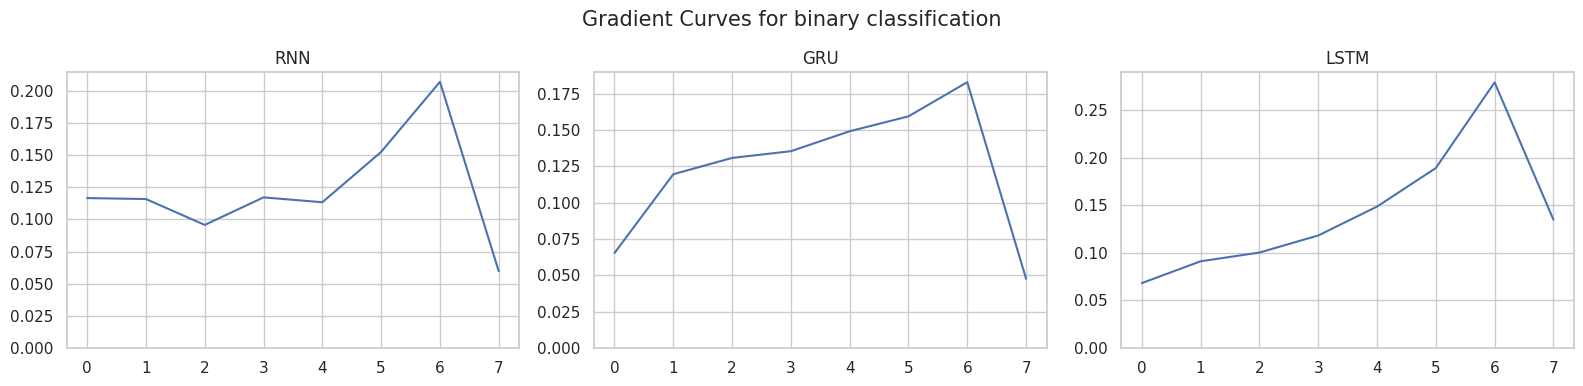

In [71]:
frobenius_norm_rnn = torch.linalg.norm(all_epochs_grads_rnn, dim=(2, 3), ord="fro")
frobenius_mean_rnn = frobenius_norm_rnn.mean(dim=0)

frobenius_norm_gru = torch.linalg.norm(all_epochs_grads_gru, dim=(2, 3), ord="fro")
frobenius_mean_gru = frobenius_norm_gru.mean(dim=0)

frobenius_norm_lstm = torch.linalg.norm(all_epochs_grads_lstm, dim=(2, 3), ord="fro")
frobenius_mean_lstm = frobenius_norm_lstm.mean(dim=0)


fig, axes = plt.subplots(ncols=3, nrows=1, figsize=(16, 4))
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_rnn, ax=axes[0])
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_gru, ax=axes[1])
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_lstm, ax=axes[2])

for ax, nm in zip(axes, ["RNN", "GRU", "LSTM"]):
  ax.set_title(nm)
  ax.set_ylabel("")
  ax.set_ylim(bottom=0)
  ax.set_xticks(range(0, max_name_lenght))

fig.suptitle("Gradient Curves for binary classification", y=0.96, fontsize=15)
plt.tight_layout()
plt.show()

<h3>With all off the model the gradients are starting to vanish as more epochs they are being trained.</h3>

### Repeating the steps for multi-class prediction, meaning that computing the loss for predicting the next letters for name.

In [72]:
# Resetting the model weights
for model in [drnn, dgru, dlstm]:
  for layer in model.children():
    if hasattr(layer, 'reset_parameters'):
        layer.reset_parameters()

# As well as the optimizers
optimizer_drnn = optim.Adam(drnn.parameters())
optimizer_dgru = optim.Adam(dgru.parameters())
optimizer_dlstm = optim.Adam(dlstm.parameters())

scheduler_rnn = optim.lr_scheduler.StepLR(optimizer_rnn, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_gru = optim.lr_scheduler.StepLR(optimizer_gru, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_lstm = optim.lr_scheduler.StepLR(optimizer_lstm, step_size=5, gamma=0.15, last_epoch=-1)

In [73]:
%%time
n_epochs = 10
all_epochs_grads_rnn = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)
all_epochs_grads_gru = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)
all_epochs_grads_lstm = torch.zeros(n_epochs, max_name_lenght, len(id_to_token), 64)

for epoch in range(n_epochs):
  with HiddenPrints():
    drnn.embedding.epoch_grads.zero_()
    dgru.embedding.epoch_grads.zero_()
    dlstm.embedding.epoch_grads.zero_()

    train(model=drnn, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_drnn, device=device, task="char")
    train(model=dgru, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_dgru, device=device, task="char")
    train(model=dlstm, dataloader=train_loader_db, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_dlstm, device=device, task="char")

    scheduler_rnn.step()
    scheduler_gru.step()
    scheduler_lstm.step()

    all_epochs_grads_rnn[epoch] = drnn.embedding.epoch_grads.clone()
    all_epochs_grads_gru[epoch] = dgru.embedding.epoch_grads.clone()
    all_epochs_grads_lstm[epoch] = dlstm.embedding.epoch_grads.clone()
print("Training finished..")

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


Training finished..
CPU times: user 35.9 s, sys: 93.9 ms, total: 36 s
Wall time: 36.3 s


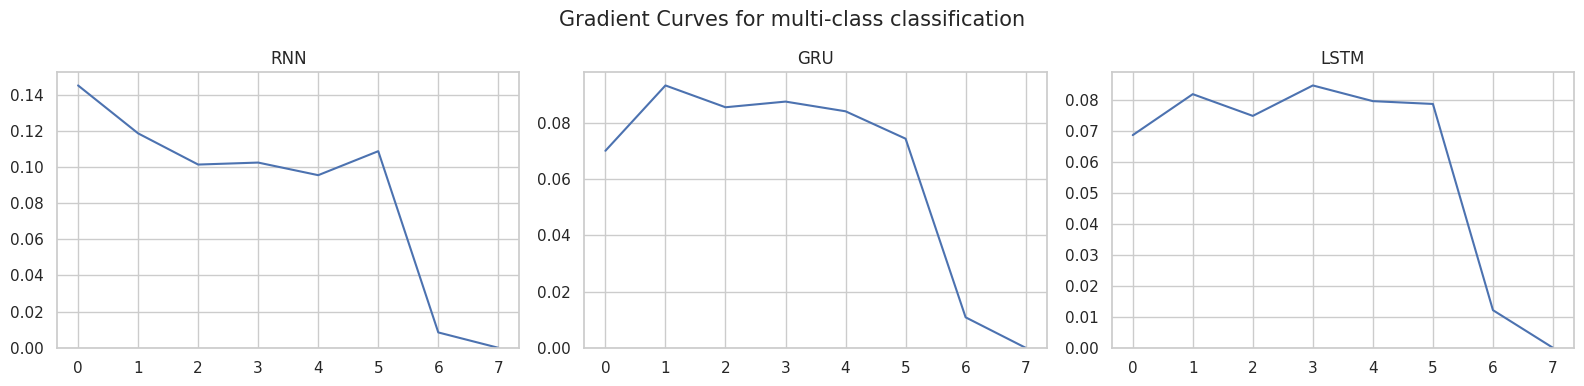

In [74]:
frobenius_norm_rnn = torch.linalg.norm(all_epochs_grads_rnn, dim=(2, 3), ord="fro")
frobenius_mean_rnn = frobenius_norm_rnn.mean(dim=0)

frobenius_norm_gru = torch.linalg.norm(all_epochs_grads_gru, dim=(2, 3), ord="fro")
frobenius_mean_gru = frobenius_norm_gru.mean(dim=0)

frobenius_norm_lstm = torch.linalg.norm(all_epochs_grads_lstm, dim=(2, 3), ord="fro")
frobenius_mean_lstm = frobenius_norm_lstm.mean(dim=0)


fig, axes = plt.subplots(ncols=3, nrows=1, figsize=(16, 4))
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_rnn, ax=axes[0])
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_gru, ax=axes[1])
sns.lineplot(x=range(0, max_name_lenght), y=frobenius_mean_lstm, ax=axes[2])

for ax, nm in zip(axes, ["RNN", "GRU", "LSTM"]):
  ax.set_title(nm)
  ax.set_ylabel("")
  ax.set_ylim(bottom=0)
  ax.set_xticks(range(0, max_name_lenght))

fig.suptitle("Gradient Curves for multi-class classification", y=0.96, fontsize=15)
plt.tight_layout()
plt.show()

<h3>The same problem, or even worse.</h3>

### Why did we used the subset of the training data with fixed-length names?

We forced all sequences to be the exact same length to align the loss injection point.

If sequences varied in length, the final prediction (where the massive gradient enters the network) would happen at t=5 for one name, and t=12 for another. If we average the gradient norms at t=5, we are averaging the end of one sequence (huge gradient) with the middle of another (decayed gradient). By fixing the length to the mode, t=0 is always exactly the exact same temporal distance from the end of the sequence across the entire batch, giving us a mathematically pure visualization of the gradient decay.

## Multitask Learning | Both BCELoss() and CrossEntropyLoss()

### Training the GRU or LSTM model with 2 loss functions at the same time: the first is the loss for predicting the next letter, the second is the loss for gender classification.

In [75]:
%%time
rnn = FullRNN(len(id_to_token), hidden_size=512)
gru = FullGRU(len(id_to_token), hidden_size=512)
lstm = FullLSTM(len(id_to_token), hidden_size=512)
rnn = rnn.to(device)
gru = gru.to(device)
lstm = lstm.to(device)

optimizer_rnn = optim.Adam(rnn.parameters())
optimizer_gru = optim.Adam(gru.parameters())
optimizer_lstm = optim.Adam(lstm.parameters())

scheduler_rnn = optim.lr_scheduler.StepLR(optimizer_rnn, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_gru = optim.lr_scheduler.StepLR(optimizer_gru, step_size=5, gamma=0.15, last_epoch=-1)
scheduler_lstm = optim.lr_scheduler.StepLR(optimizer_lstm, step_size=5, gamma=0.15, last_epoch=-1)

# The loss functions
loss_multi = nn.CrossEntropyLoss(ignore_index=0)
loss_bin = nn.BCELoss()

CPU times: user 23 ms, sys: 5 ms, total: 28 ms
Wall time: 28.1 ms


In [76]:
%%time
res_rnn = pd.DataFrame(columns=["epoch", "model", "dataset", "Loss(multi)", "Loss(binary)"])
res_gru = pd.DataFrame(columns=["epoch", "model", "dataset", "Loss(multi)", "Loss(binary)"])
res_lstm = pd.DataFrame(columns=["epoch", "model", "dataset", "Loss(multi)", "Loss(binary)"])

n_epochs = 10
for epoch in range(n_epochs):
  print(f"Epoch {epoch+1:02d}:")
  with HiddenPrints():
    rnn_train = train(model=rnn, dataloader=train_loader, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_rnn, device=device, task="both")
    rnn_test = test(model=rnn, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device)
    scheduler_rnn.step()

    gru_train = train(model=gru, dataloader=train_loader, loss_multi=loss_multi, loss_bin=loss_bin, optimizer=optimizer_gru, device=device, task="both")
    gru_test = test(model=gru, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device)
    scheduler_gru.step()

    lstm_train = train(model=lstm, dataloader=train_loader, loss_multi=loss_multi, loss_bin = loss_bin, optimizer=optimizer_lstm, device=device, task="both")
    lstm_test = test(model=lstm, dataloader=valid_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device)
    scheduler_lstm.step()

  # train() => avg_loss_chars, avg_loss_genders
  # test() => avg_loss_chars, avg_loss_genders
  res_rnn.loc[len(res_rnn)] = [epoch+1, "RNN", "train", rnn_train[0], rnn_train[1]]
  res_rnn.loc[len(res_rnn)] = [epoch+1, "RNN", "valid", rnn_test[0], rnn_test[1]]

  res_gru.loc[len(res_gru)] = [epoch+1, "GRU", "train", gru_train[0], gru_train[1]]
  res_gru.loc[len(res_gru)] = [epoch+1, "GRU", "valid", gru_test[0], gru_test[1]]

  res_lstm.loc[len(res_lstm)] = [epoch+1, "LSTM", "train", lstm_train[0], lstm_train[1]]
  res_lstm.loc[len(res_lstm)] = [epoch+1, "LSTM", "valid", lstm_test[0], lstm_test[1]]

print("Finished.")

Epoch 01:
Epoch 02:
Epoch 03:
Epoch 04:
Epoch 05:
Epoch 06:
Epoch 07:
Epoch 08:
Epoch 09:
Epoch 10:
Finished.
CPU times: user 1min 26s, sys: 254 ms, total: 1min 26s
Wall time: 1min 27s


### Evaluation

#### Potting loss convergence for both loss functions on training and valid data.

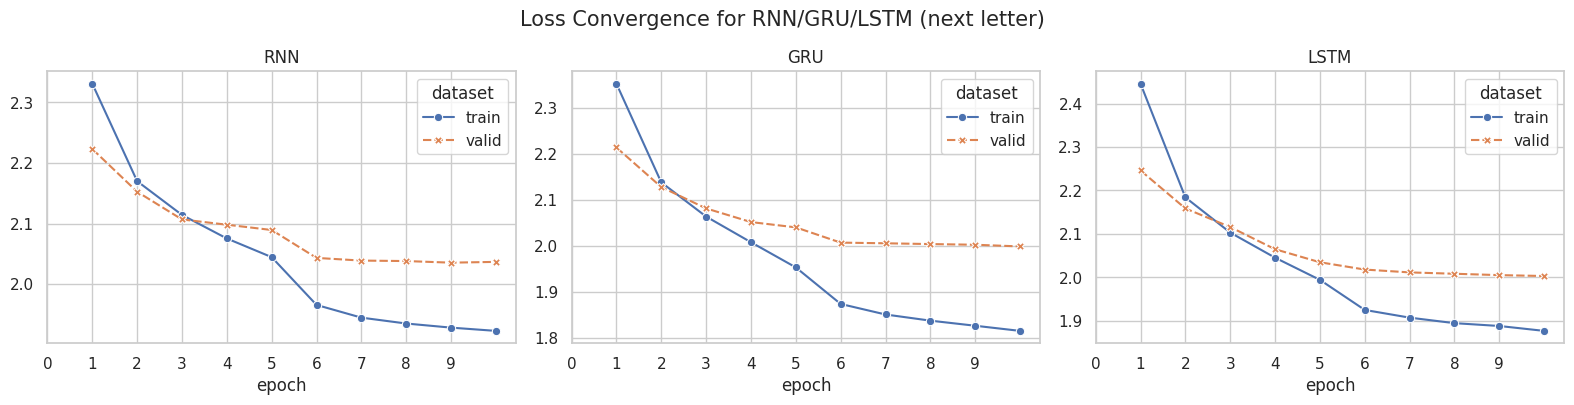

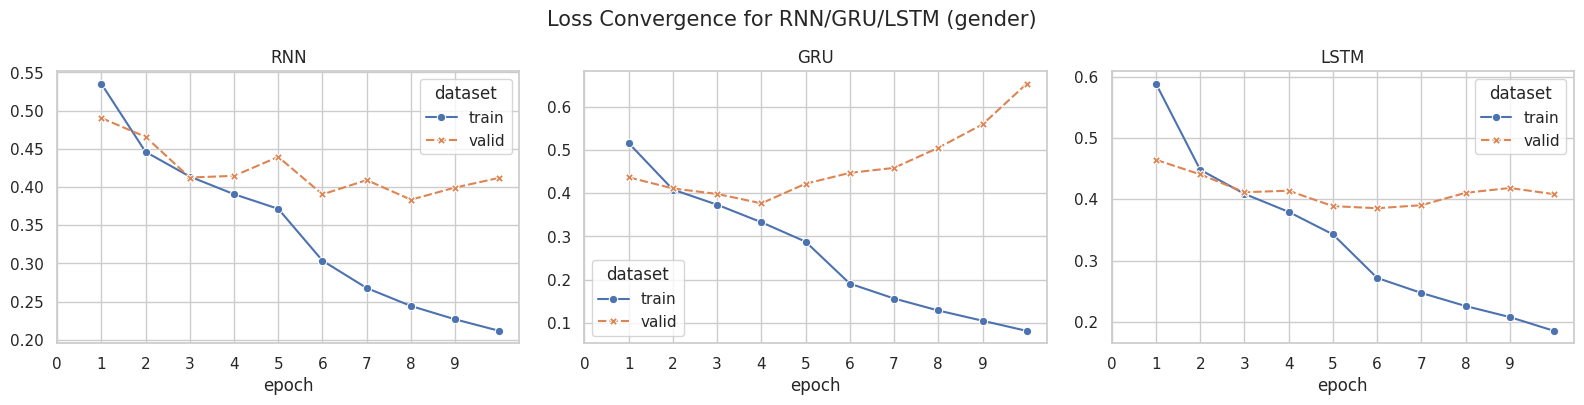

In [77]:
fig, axesm = plt.subplots(ncols=3, nrows=1, figsize=(16, 4.2))
sns.lineplot(data=res_rnn, x="epoch", y="Loss(multi)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesm[0])
sns.lineplot(data=res_gru, x="epoch", y="Loss(multi)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesm[1])
sns.lineplot(data=res_lstm, x="epoch", y="Loss(multi)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesm[2])
fig.suptitle("Loss Convergence for RNN/GRU/LSTM (next letter)", y=0.96, fontsize=15)

for ax, nm in zip(axesm, ["RNN", "GRU", "LSTM"]):
  ax.set_title(nm)
  ax.set_ylabel("")
  ax.set_xticks(range(0, n_epochs))

plt.tight_layout()


fig, axesb = plt.subplots(ncols=3, nrows=1, figsize=(16, 4.2))
sns.lineplot(data=res_rnn, x="epoch", y="Loss(binary)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesb[0])
sns.lineplot(data=res_gru, x="epoch", y="Loss(binary)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesb[1])
sns.lineplot(data=res_lstm, x="epoch", y="Loss(binary)", hue="dataset", markers=True, style="dataset", legend="brief", ax=axesb[2])
fig.suptitle("Loss Convergence for RNN/GRU/LSTM (gender)", y=0.96, fontsize=15)

for ax, nm in zip(axesb, ["RNN", "GRU", "LSTM"]):
  ax.set_title(nm)
  ax.set_ylabel("")
  ax.set_xticks(range(0, n_epochs))

plt.tight_layout()
plt.show()

<h3>GRU model is overfitting pretty significantly for gender classification task.</h3>

#### Sample names

In [78]:
genn = pd.DataFrame(columns=['model', 'name'])
for model in [rnn, gru, lstm]:
  md = model.__class__.__name__
  for _ in range(10):
    name = generate_name(
        model = model,
        id_to_token = id_to_token,
        token_to_id = token_to_id,
        temperature=np.random.uniform(0.5, 1.5),
        max_range=random.randrange(4, 14),
        device=device,
        retn=True)
    genn.loc[len(genn)] = [md, name]

genn = genn.assign(row=genn.groupby("model").cumcount()).pivot(index="row", columns="model", values="name").reset_index(drop=True)

In [79]:
genn

model,FullGRU,FullLSTM,FullRNN
0,mich,waltos,laug
1,sandaro,aulyn,ayanne
2,odton,jar,laviana
3,kiksber,zancy,veribiebar
4,marche,daj,sharin
5,patri,ellia,agya
6,pata,tonie,aline
7,terol,joretta,eyshon
8,douge,frob,jayne
9,zenneed,bernol,durten


<h3> But not so bad.</h3>

#### AUC_ROC score

In [80]:
for model in [rnn, gru, lstm]:
  print(f"{model.__class__.__name__}:")
  test(model=model, dataloader=test_loader, loss_multi=loss_multi, loss_bin=loss_bin, device=device, roc_auc=roc_auc_score)

FullRNN:
     ROC AUC score (test/avg): 0.9174
     Loss (testing): characters(multi): 1.9869 | gender(binary): 0.3984
     Accuracy (avg): characters(multi): 37.15% | gender(binary): 85.13%
FullGRU:
     ROC AUC score (test/avg): 0.9253
     Loss (testing): characters(multi): 1.9353 | gender(binary): 0.5155
     Accuracy (avg): characters(multi): 37.87% | gender(binary): 86.45%
FullLSTM:
     ROC AUC score (test/avg): 0.9208
     Loss (testing): characters(multi): 1.9576 | gender(binary): 0.4012
     Accuracy (avg): characters(multi): 38.32% | gender(binary): 83.95%


<h3>Yeah, not so bad.</h3>

## Visualizing the embeddings for each letter

In [81]:
embeddings_weight = lstm.embedding.weight.detach().cpu().numpy()
tokens = [id_to_token[i] for i in range(len(id_to_token))]

special_tokens = {'<SOS>', '<EOS>', '0', '1', '2'}
vowels = {'a', 'e', 'i', 'o', 'u', 'y'}

filtered_indices = [i for i, t in enumerate(tokens) if t not in special_tokens]
filtered_tokens = [tokens[i] for i in filtered_indices]
filtered_embeddings = embeddings_weight[filtered_indices]


categories = []
for token in filtered_tokens:
    if token.lower() in vowels:
        categories.append('Vowel')
    else:
        categories.append('Consonant')

df_emb = pd.DataFrame({
    'token': filtered_tokens,
    'category': categories
})

#### We use TSNE model to compress vectors into 2 dimensions, and split the letters into vowels and consonants.


In [82]:
tsne = TSNE(n_components=2, perplexity=5, random_state=42, max_iter=1000, learning_rate='auto')
tsne_results = tsne.fit_transform(filtered_embeddings)
df_emb['tSNE_1'] = tsne_results[:, 0]
df_emb['tSNE_2'] = tsne_results[:, 1]

#### Also PCA.

In [83]:
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(filtered_embeddings)
df_emb['PCA_1'] = pca_results[:, 0]
df_emb['PCA_2'] = pca_results[:, 1]

#### Visalization

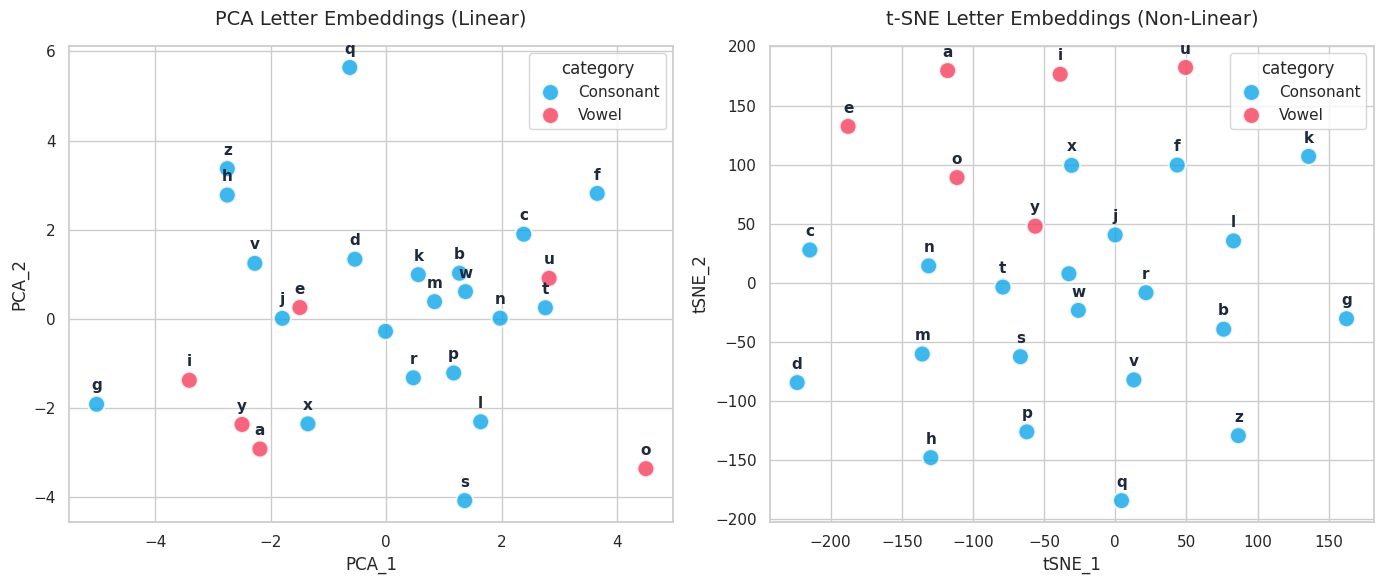

In [84]:
sns.set_theme(style="whitegrid")
palette = {'Vowel': '#f43f5e', 'Consonant': '#0ea5e9'}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PCA
sns.scatterplot(
    data=df_emb, x='PCA_1', y='PCA_2', hue='category',
    palette=palette, s=150, alpha=0.8, ax=axes[0], edgecolor='w', linewidth=1.5
)
axes[0].set_title("PCA Letter Embeddings (Linear)", fontsize=14, pad=15)

# t-SNE
sns.scatterplot(
    data=df_emb, x='tSNE_1', y='tSNE_2', hue='category',
    palette=palette, s=150, alpha=0.8, ax=axes[1], edgecolor='w', linewidth=1.5
)
axes[1].set_title("t-SNE Letter Embeddings (Non-Linear)", fontsize=14, pad=15)

for i, row in df_emb.iterrows():
    axes[0].annotate(
        row['token'], (row['PCA_1'], row['PCA_2']),
        textcoords="offset points", xytext=(0,10), ha='center',
        fontsize=11, fontweight='bold', color='#1e293b')

    axes[1].annotate(
        row['token'], (row['tSNE_1'], row['tSNE_2']),
        textcoords="offset points", xytext=(0,10), ha='center',
        fontsize=11, fontweight='bold', color='#1e293b')

plt.tight_layout()
plt.show()

### What can we infer from the plots?

For:
#### <strong>t-SNE</strong>

Notice how vowels form a prominent horizontal "wall" along the top.
In a gender classification task for names, vowels carry massive predictive weight because they dictate name endings (e.g., names ending in -a, -e, or -i are heavily correlated with feminine names in many datasets). The network has separated these vowels into distinct spatial coordinates because they serve as critical conditional switch-points for the gender classification head.


#### <strong>PCA</strong>

In the bottom right of the PCA plot vowel "o" has its own distinct spatial coordinate. Also other voewls "i", "y", "a" are kinda grouped together around the bottom-left side. If you remember the beginning of this notebook there I had plotted the frequency of the words, and these specifically "a" and "i" were extremely freequent, so they are located closesly in this dimension.

Also you can notice that "q" letter is the most top on the PCA and most bottom on the t-SNE plots, because again, if you remember the frequency chart it was, if not one of the most least used letters in names.

### Saving the model for later use.

In [85]:
joblib.dump(lstm, 'data/lstm.pkl')

['data/lstm.pkl']

And done!